# Office hours. Теория вероятностей: независимость, условная и геометрическая вероятность, Монте-Карло

In [ ]:
import math, random, itertools
import numpy as np
import matplotlib.pyplot as plt
from typing import Callable, List, Tuple

w = 32  # служебная переменная для форматирования
random.seed(42)

print('Импорты загружены.')

Импорты загружены.


---

## Задача 1. Независимость и составные события

События $A$, $B$, $C$ независимы в совокупности, $P(A) = 0.8$, $P(B) = 0.6$, $P(C) = 0.3$. Найдите:

**(а)** вероятность того, что произойдёт **ровно одно** из трёх событий;

**(б)** вероятность того, что произойдёт **хотя бы одно** из них. Объясните, почему ответ нельзя получить сложением $0.8 + 0.6 + 0.3$;

**(в)** вероятность того, что произошло ровно одно событие, **если известно**, что произошло хотя бы одно.

### Теория

Обозначение: $AB := A \cap B$, $\bar A$ — дополнение (событие $A$ не произошло).

**1. Независимость в совокупности.** События $A, B, C$ независимы в совокупности, если для **любого** их поднабора вероятность пересечения равна произведению вероятностей:
$$P(AB) = P(A)P(B),\quad P(AC) = P(A)P(C),\quad P(BC) = P(B)P(C),\quad P(ABC) = P(A)P(B)P(C).$$
Первых трёх равенств (попарной независимости) **недостаточно**. Пример: две честные монеты, $A$ = «на первой орёл», $B$ = «на второй орёл», $C$ = «монеты выпали одинаково». Любые два события независимы: например, $P(AC) = P(\text{оба орла}) = \tfrac14 = \tfrac12 \cdot \tfrac12$. Но $P(ABC) = \tfrac14 \ne \tfrac18$: если известны $A$ и $B$, то $C$ известно точно. Поэтому перемножать вероятности трёх и более событий можно только при независимости в совокупности.

**2. Дополнения независимых событий независимы.** Событие $AC$ разбивается на несовместные части $ABC$ и $A\bar B C$, поэтому
$$P(A\bar B C) = P(AC) - P(ABC) = P(A)P(C) - P(A)P(B)P(C) = P(A)\bigl(1 - P(B)\bigr)P(C) = P(A)P(\bar B)P(C).$$
Вместо $AC$ можно взять пересечение любых других событий набора (для любого их числа): шаг тот же. Так по одному заменяем любые события на дополнения — равенства из п. 1 сохраняются для всех поднаборов. Например, $P(\bar A\bar B C) = 0.2 \cdot 0.4 \cdot 0.3$.

**3. Приём «несовместные сценарии».** Сценарий — это указание для каждого события, произошло оно или нет (например, $A\bar B\bar C$). Для трёх событий сценариев $2^3 = 8$, и они разбивают $\Omega$. Два разных сценария **несовместны автоматически**: в одном есть $A$, в другом $\bar A$ (или так по другому событию). Отсюда правило:
- составное событие = объединение подходящих сценариев, **между сценариями складываем**;
- **внутри сценария перемножаем** (п. 1–2).

**4. Несовместные ≠ независимые.** Пусть $P(A) > 0$, $P(B) > 0$ и $A$, $B$ несовместны. Тогда $P(AB) = 0 \ne P(A)P(B)$, то есть такие события **зависимы**: наступление $A$ гарантирует, что $B$ не наступило. Иначе говоря: независимые события с ненулевыми вероятностями всегда пересекаются, $P(AB) = P(A)P(B) > 0$.

**5. Условная вероятность.** $P(E \mid F) = \dfrac{P(EF)}{P(F)}$ при $P(F) > 0$. Смысл: знание «произошло $F$» сужает $\Omega$ до $F$ — исходы вне $F$ выбрасываются, от $E$ остаётся только $EF$, а вероятности оставшихся делятся на $P(F)$, чтобы в сумме снова получилась 1. Если $E \subset F$, то $EF = E$ и $P(E \mid F) = P(E)/P(F)$.

### Решение

Вероятности дополнений: $P(\bar A) = 0.2$, $P(\bar B) = 0.4$, $P(\bar C) = 0.7$.

**(а) Ровно одно.** Подходят три несовместных сценария: «только $A$», «только $B$», «только $C$». Складываем их, а внутри каждого перемножаем (п. 2–3):
$$P(\text{ровно одно}) = P(A\bar B\bar C) + P(\bar A B\bar C) + P(\bar A\bar B C) = 0.8\cdot0.4\cdot0.7 + 0.2\cdot0.6\cdot0.7 + 0.2\cdot0.4\cdot0.3$$
$$= 0.224 + 0.084 + 0.024 = \mathbf{0.332}.$$

**(б) Хотя бы одно.** Подходят 7 сценариев из 8, а дополнение состоит из одного сценария «не произошло ни одно» $= \bar A\bar B\bar C$:
$$P(A \cup B \cup C) = 1 - P(\bar A\bar B\bar C) = 1 - 0.2\cdot0.4\cdot0.7 = 1 - 0.056 = \mathbf{0.944}.$$
Почему не $0.8 + 0.6 + 0.3 = 1.7$: сложение верно только для несовместных событий, а $A$, $B$, $C$ пересекаются (п. 4: $P(AB) = 0.48 > 0$). В сумме $P(A) + P(B) + P(C)$ сценарий, где произошли два события, посчитан дважды, а где три — трижды.

**(в) Ровно одно при условии «хотя бы одно».** Пусть $E$ = «ровно одно», $F$ = «хотя бы одно». Если произошло ровно одно событие, то хотя бы одно тоже произошло: $E \subset F$, поэтому $EF = E$ (п. 5):
$$P(E \mid F) = \frac{P(EF)}{P(F)} = \frac{P(E)}{P(F)} = \frac{0.332}{0.944} \approx \mathbf{0.3517}.$$ Проверим числа перебором всех 8 сценариев:

In [ ]:
# Проверка: перебираем все 2^3 = 8 сценариев (True — событие произошло)
ps = [0.8, 0.6, 0.3]  # P(A), P(B), P(C)

p_exactly_one = 0.0
p_at_least_one = 0.0
for outcome in itertools.product([True, False], repeat=len(ps)):
    # вероятность сценария: произведение p или (1 - p) — по независимости
    weight = math.prod(p if happened else 1 - p for p, happened in zip(ps, outcome))
    k = sum(outcome)  # сколько событий произошло в этом сценарии
    if k == 1:
        p_exactly_one += weight   # сценарии несовместны — складываем
    if k >= 1:
        p_at_least_one += weight

print(f"━━━ Задача 1: перебор сценариев ━━━")
print(f"  {'(а) P(ровно одно):':<{w}} {p_exactly_one:.4f}")
print(f"  {'(б) P(хотя бы одно):':<{w}} {p_at_least_one:.4f}")
print(f"  {'(б) наивная сумма P:':<{w}} {sum(ps):.4f}")
print(f"  {'(в) P(ровно 1 | хотя бы 1):':<{w}} {p_exactly_one / p_at_least_one:.4f}")

━━━ Задача 1: перебор сценариев ━━━
  (а) P(ровно одно):               0.3320
  (б) P(хотя бы одно):             0.9440
  (б) наивная сумма P:             1.7000
  (в) P(ровно 1 | хотя бы 1):      0.3517


---

## Задача 2. Полная вероятность и Байес: допинг-контроль

На турнире 2% спортсменов употребляют допинг. Тест даёт положительный результат («+») у нарушителя с вероятностью 0.95, а у «чистого» спортсмена — с вероятностью 0.05 (ложная тревога). Тестируют случайно выбранного спортсмена.

- **(а)** Найдите вероятность того, что тест окажется положительным.
- **(б)** Тест положителен. Какова вероятность, что спортсмен действительно нарушитель? Сравните ответ с вероятностью события «спортсмен — нарушитель **и** тест положителен», а также с числом 0.95.
- **(в)** Тест отрицателен. Какова вероятность, что спортсмен всё-таки нарушитель?

Обозначения: $D$ — «нарушитель», $\bar D$ — «чистый», $+$ / $-$ — результат теста. Дано: $P(D)=0.02$, $P(+\mid D)=0.95$, $P(+\mid \bar D)=0.05$.

### Теория

**1. Условная вероятность и правило умножения.**
Определение $P(A\mid B)=\dfrac{P(A\cap B)}{P(B)}$ и его смысл (сужаем $\Omega$ до $B$ и перенормируем) — см. задачу 1, п. 5. Нам понадобится следствие: при фиксированном условии $P(\,\cdot\mid D)$ — обычная вероятность, поэтому $P(-\mid D)=1-P(+\mid D)$.

То же определение, переписанное через умножение, — **правило умножения**: $P(A\cap B)=P(B)\,P(A\mid B)$. Оно нужно, потому что в условиях обычно даны *условные* вероятности («как тест ведёт себя у нарушителя»), а совместные приходится получать из них: $P(D\cap +)=P(D)\,P(+\mid D)$.

**2. Формула полной вероятности.** События $H_1,\dots,H_n$ образуют *полную группу гипотез*, если они попарно несовместны и в объединении дают всё $\Omega$ (всегда происходит ровно одна). Тогда для любого события $A$
$$P(A)=\sum_{i=1}^{n} P(H_i)\,P(A\mid H_i).$$
Почему: $A=(A\cap H_1)\cup\dots\cup(A\cap H_n)$, и каждый исход из $A$ попадает ровно в один кусок, т.е. куски несовместны и их вероятности складываются; каждый кусок раскрываем правилом умножения $P(A\cap H_i)=P(H_i)\,P(A\mid H_i)$.

**3. Формула Байеса.**
$$P(H_k\mid A)=\frac{P(H_k)\,P(A\mid H_k)}{\sum_{i} P(H_i)\,P(A\mid H_i)}.$$

### Решение

**Дерево в виде таблицы.** Гипотезы $D,\ \bar D$ — полная группа. $P(\bar D)=0.98$, $P(-\mid D)=1-0.95=0.05$, $P(-\mid\bar D)=1-0.05=0.95$. Вероятность ветви = $P(H)\cdot P(\text{результат}\mid H)$:

| Гипотеза $H$ | $P(H)$ | $P(+\mid H)$ | ветвь «$H$ и +» | $P(-\mid H)$ | ветвь «$H$ и −» |
|:--|:-:|:-:|:-:|:-:|:-:|
| $D$ | 0.02 | 0.95 | $0.02\cdot0.95=0.019$ | 0.05 | $0.02\cdot0.05=0.001$ |
| $\bar D$ | 0.98 | 0.05 | $0.98\cdot0.05=0.049$ | 0.95 | $0.98\cdot0.95=0.931$ |
| **сумма** | 1 | | **0.068** | | **0.932** |

**(а)** Формула полной вероятности — сумма ветвей с «+»:
$$P(+)=P(D)P(+\mid D)+P(\bar D)P(+\mid\bar D)=0.019+0.049=0.068.$$

**(б)** Байес — доля ветви $D$ среди ветвей с «+»:
$$P(D\mid +)=\frac{P(D\cap +)}{P(+)}=\frac{0.019}{0.068}\approx 0.279.$$

**(в)** $P(-)=1-0.068=0.932$ (или сумма ветвей с «−»: $0.001+0.931$). По Байесу
$$P(D\mid -)=\frac{P(D\cap -)}{P(-)}=\frac{0.001}{0.932}\approx0.00107\approx0.0011,$$
почти в 19 раз меньше исходных 2%: отрицательный тест почти «оправдывает».

---

## Задача 3. Точный перебор + Монте-Карло

Команда в квест-комнате должна решить 4 загадки. Загадки решаются **независимо** с вероятностями
$p_1 = 0.9,\ p_2 = 0.75,\ p_3 = 0.65,\ p_4 = 0.4$. Дверь открывается, если решено **не менее трёх** загадок.

1. Напишите функцию `exact_probability(ps, condition)`, которая точно считает вероятность любого события,
   заданного функцией-условием `condition(outcome) -> bool` на кортеже из `True/False`, — перебором всех $2^n$ исходов.
2. Напишите `monte_carlo(ps, condition, iterations)` на библиотеке `random` и сравните с точным ответом для «дверь открыта».
3. Не трогая движок, смените условие одной строкой: «решены **ровно две** загадки».
4. Найдите $P(\text{дверь открыта} \mid \text{первая загадка решена})$ точно (тем же движком) и проверьте методом Монте-Карло.

### Теория

**1. Вес исхода и сумма весов (как в задаче 1, п. 2–3).** Пусть $A_i$ = «решена загадка $i$». Исход — вектор
$\omega = (b_1, \dots, b_n)$, где $b_i = 1$, если произошло $A_i$, и $b_i = 0$, если $\bar A_i$. По независимости в совокупности
(с дополнениями)
$$P(\omega) = \prod_{i=1}^{n} p_i^{\,b_i} (1 - p_i)^{1 - b_i}, \qquad \text{например, } P(1, 1, 0, 1) = 0.9 \cdot 0.75 \cdot 0.35 \cdot 0.4.$$
Разные исходы несовместны, поэтому $P(E) = \sum_{\omega \in E} P(\omega)$ — для **любого** логического условия $E$.
Исходы **не равновероятны**: делить «число благоприятных на $2^n$» нельзя.

**2. Почему `random.random() < p` — событие вероятности $p$.** `random.random()` даёт $U \sim U[0, 1)$, и $P(U < p) = p$.
Для каждой загадки нужен **свой** вызов `random.random()`. Если сравнивать одно и то же $U$ с разными $p_i$,
события станут зависимыми.

**3. Почему МК сходится.** Предмет обсуждения на лекциях - по сути ЗБЧ (что сходится) + ЦПТ (как быстро). Про корректность обусловленного подсчета - в задаче 4.

**4. Условие на независимую компоненту.** $P(E \mid F) = \dfrac{P(E \cap F)}{P(F)}$ (задача 1, п. 5). Пусть $F = A_1$.
Тогда в каждом слагаемом числителя стоит множитель $p_1$ ($b_1 = 1$), а знаменатель $P(A_1) = p_1$; множитель сокращается:
$$P(E \mid A_1) = \frac{\sum_{\omega:\ b_1 = 1,\ \omega \in E} p_1 \prod_{i \ge 2} p_i^{\,b_i}(1 - p_i)^{1 - b_i}}{p_1}
= \sum_{(b_2, \dots, b_n):\ (1, b_2, \dots, b_n) \in E} \ \prod_{i \ge 2} p_i^{\,b_i}(1 - p_i)^{1 - b_i},$$
то есть условие просто **фиксирует** $b_1 = 1$, а остальные компоненты (независимые от первой) живут как без условия:
перебор идёт только по $b_2, \dots, b_n$.

В МК то же определение реализуется **отбором**: оставляем только итерации, где выполнено $F$ (это и есть «новая $\Omega$»),
и считаем долю $E$ среди них — делим на число **отобранных** итераций, а не на $N$
(почему отношение частот сходится к условной вероятности — задача 4, шаг 3).

$$
P(M) = P(\bar M) = \frac{1}{2} \\
P(D|M) = \frac{1}{200} \\
P(D|\bar M) = \frac{1}{400} \\
D \bar D + \bar D D = B \\
P(D \bar D + \bar D D) = 2 P(D \bar D) =  2 P(D) (1 - P( D)) = 2 \frac{3 \cdot 797}{800^2} \\
P(D) = P(D | M) \cdot P(M) + P(D | \bar M) \cdot P(\bar M) = \frac{3}{800} \\
P(D \bar D | MM) =  \frac{199}{200^2}\\
P(MM | D \bar D + \bar D D) = P(MM | B) = \frac{\frac{1}{4} \cdot \frac{2 \cdot 199}{200^2}}{2 \frac{3 \cdot 797}{800^2}} = \cdots
$$

**3. Формула Байеса.**
$$P(H_k\mid A)=\frac{P(H_k)\,P(A\mid H_k)}{\sum_{i} P(H_i)\,P(A\mid H_i)}.$$

### Решение

In [ ]:
Outcome = Tuple[bool, ...]


def outcome_weight(
    ps: List[float],
    outcome: Outcome
) -> float:
    """Вероятность одного исхода: произведение p_i (решена) или 1 - p_i (не решена)."""

    weight = 1.0
    for p, solved in zip(ps, outcome):
        weight *= p if solved else 1 - p
    return weight


def exact_probability(
    ps: List[float],
    condition: Callable[[Outcome], bool]
) -> float:
    """Точная вероятность события: сумма весов всех 2^n исходов, где выполнено условие."""

    return sum(
        outcome_weight(ps, outcome)
        for outcome in itertools.product([True, False], repeat=len(ps))
        if condition(outcome)
    )


def monte_carlo(
    ps: List[float],
    condition: Callable[[Outcome], bool],
    iterations: int = 1_000_000
) -> float:
    """Оценка вероятности события методом Монте-Карло."""

    successful_experiments = 0
    for _ in range(iterations):
        # для каждой загадки — СВОЙ вызов random.random(), иначе события станут зависимыми
        outcome = tuple(random.random() < p for p in ps)
        if condition(outcome):
            successful_experiments += 1
    return successful_experiments / iterations


def door_opens(outcome: Outcome) -> bool:
    """Дверь открывается, если решено не менее трёх загадок (True считается как 1)."""

    return sum(outcome) >= 3

In [ ]:
import time


def compare(
    title: str,
    ps: List[float],
    condition: Callable[[Outcome], bool]
) -> None:
    """Печатает точный ответ, оценку МК и их разность."""

    start_time = time.time()
    exact = exact_probability(ps, condition)
    mc = monte_carlo(ps, condition)
    execution_time = time.time() - start_time
    rel_diff = abs(exact - mc) / exact * 100

    print(f"━━━ {title} ━━━")
    print(f"  {'Точный перебор:':<{w}} {exact:.6f}")
    print(f"  {'Монте-Карло:':<{w}} {mc:.6f}")
    print(f"  {'Абсолютная разность:':<{w}} {abs(exact - mc):.6f}")
    print(f"  {'Относительная разность:':<{w}} {rel_diff:.4f}%")
    print(f"  {'Время расчёта:':<{w}} {execution_time:.3f} сек.")


random.seed(3)  # своё зерно: числа МК не зависят от порядка ячеек
ps = [0.9, 0.75, 0.65, 0.4]
compare("Дверь открыта (решено ≥ 3 из 4)", ps, door_opens)

━━━ Дверь открыта (решено ≥ 3 из 4) ━━━
  Точный перебор:                  0.611250
  Монте-Карло:                     0.610666
  Абсолютная разность:             0.000584
  Относительная разность:          0.0955%
  Время расчёта:                   0.500 сек.


Новое событие — меняется **только** функция-условие:

In [ ]:
random.seed(33)
compare("Решены ровно две", ps, lambda outcome: sum(outcome) == 2)

━━━ Решены ровно две ━━━
  Точный перебор:                  0.307250
  Монте-Карло:                     0.306848
  Абсолютная разность:             0.000402
  Относительная разность:          0.1308%
  Время расчёта:                   0.464 сек.


Условие «первая решена» фиксирует $b_1 = 1$: двери остаётся набрать $\ge 2$ решённых из загадок 2–4 — тот же движок
на `ps[1:]`. МК — отбором итераций:

In [ ]:
def monte_carlo_given_first(
    ps: List[float],
    condition: Callable[[Outcome], bool],
    iterations: int = 1_000_000
) -> float:
    """Оценка P(condition | первая загадка решена) методом Монте-Карло (отбор итераций)."""

    selected_experiments = 0
    successful_experiments = 0
    for _ in range(iterations):
        outcome = tuple(random.random() < p for p in ps)
        if not outcome[0]:
            continue  # условие не выполнено — итерацию выбрасываем
        selected_experiments += 1
        if condition(outcome):
            successful_experiments += 1
    # делим на число ОТОБРАННЫХ итераций, а не на iterations
    return successful_experiments / selected_experiments


random.seed(4)
# условие на компоненту фиксирует b_1 = 1 → двери нужны ≥ 2 решённых из загадок 2–4 (теория, п. 4)
p_cond = exact_probability(ps[1:], lambda outcome: sum(outcome) >= 2)
mc_cond = monte_carlo_given_first(ps, door_opens)

print(f"━━━ P(дверь открыта | 1-я решена) ━━━")
print(f"  {'Точно (≥ 2 из загадок 2–4):':<{w}} {p_cond:.6f}")
print(f"  {'Монте-Карло (отбор):':<{w}} {mc_cond:.6f}")
print(f"  {'Абсолютная разность:':<{w}} {abs(p_cond - mc_cond):.6f}")
print(f"  {'P(дверь) без условия:':<{w}} {exact_probability(ps, door_opens):.6f}")

━━━ P(дверь открыта | 1-я решена) ━━━
  Точно (≥ 2 из загадок 2–4):      0.657500
  Монте-Карло (отбор):             0.658262
  Абсолютная разность:             0.000762
  P(дверь) без условия:            0.611250


---

## Задача 4. Смесь гипотез и Монте-Карло условной вероятности

В мешке лежат 3 монеты: **2 честные** и **1 несимметричная**, у которой $P(\text{орёл}) = 0.8$. Из мешка наугад достают одну монету и бросают её **4 раза**.

1. Чему равна точная вероятность получить ровно 3 орла?
2. Выпало ровно 3 орла. Какова теперь (точно) вероятность, что в руках несимметричная монета? Во сколько раз она выросла по сравнению с исходной $1/3$?
3. Оцените обе вероятности методом Монте-Карло (библиотека `random`, $10^6$ итераций). Отдельно покажите, что получится, если в условной оценке поделить на $N$.

Обозначения: $H_F$ (fair) — «достали честную монету», $H_U$ (unfair) — «достали несимметричную», $B$ — «ровно 3 орла из 4».

### Теория

**Шаг 1. Число орлов при известной монете.** Если монета выбрана и $P(\text{орёл}) = p$, броски независимы и $X \mid p \sim \operatorname{Binomial}(4, p)$:
$$P(X = k \mid p) = \binom{4}{k} p^k (1-p)^{4-k}$$
— это $\binom{4}{k}$ несовместных последовательностей, у каждой вероятность $p^k(1-p)^{4-k}$ (произведение по независимым броскам).

**Но без знания монеты броски зависимы.** $P(\text{орёл}_1) = \frac23\cdot 0.5 + \frac13\cdot 0.8 = 0.6$, но
$$P(\text{орёл}_2 \mid \text{орёл}_1) = \frac{\frac23\cdot 0.5^2 + \frac13\cdot 0.8^2}{0.6} = \frac{0.38}{0.6} \approx 0.633 \ne 0.6:$$
первый орёл «намекает» на несимметричную монету. Поэтому $X$ — **не** $\operatorname{Binomial}(4, 0.6)$, и подстановка средней $p$ даёт неверное $4\cdot 0.6^3\cdot 0.4 = 0.3456$. Правильный путь — разбить по монетам.

**Шаг 2. Полная вероятность и Байес.** $H_F, H_U$ — полная группа гипотез, поэтому
$$P(B) = P(H_F)\,P(B\mid H_F) + P(H_U)\,P(B\mid H_U), \qquad P(H_U\mid B) = \frac{P(H_U)\,P(B\mid H_U)}{P(B)}$$
— доля ветки $H_U$ среди всех ветвей, где выпало 3 орла.

**Шаг 3. Почему МК-отбор оценивает условную вероятность** (отбор уже встречался в задаче 3). Проводим $N$ независимых экспериментов (монета, затем 4 броска). Пусть $N_B$ — число экспериментов, где случилось $B$, а $N_{UB}$ — где случилось и $B$, и $H_U$. По ЗБЧ $N_{UB}/N \to P(H_U \cap B)$ и $N_B/N \to P(B) > 0$, поэтому
$$\frac{N_{UB}}{N_B} = \frac{N_{UB}/N}{N_B/N} \;\longrightarrow\; \frac{P(H_U \cap B)}{P(B)} = P(H_U \mid B).$$
То есть мы **отбрасываем** эксперименты, где условие не выполнилось, и среди оставшихся считаем частоту $H_U$. Знаменатель — $N_B$, а не $N$: деление на $N$ даёт оценку совместной вероятности.

**Моделирование.** `random.choice([0.5, 0.5, 0.8])` выбирает монету равновероятно: повтор 0.5 в списке даёт честной монете вес $2/3$. Броски — 4 независимых `random.random() < p` (см. задачу 3), их сумма $\sim \operatorname{Binomial}(4, p)$.

### Решение

In [ ]:
COINS = [0.5, 0.5, 0.8]   # P(орёл) для каждой монеты в мешке
N_TOSSES = 4              # Число бросков выбранной монеты
K_HEADS = 3               # Условие B: ровно столько орлов
P_BIASED = 0.8            # Монета, про которую спрашиваем


def binom_pmf(
    k: int,
    n: int,
    p: float
) -> float:
    """Вероятность ровно k успехов в n независимых испытаниях с вероятностью успеха p."""
    return math.comb(n, k) * p**k * (1 - p)**(n - k)


def exact_mixture(
    coins: List[float],
    n: int,
    k: int,
    p_target: float
) -> Tuple[float, float, float]:
    """Точный расчёт: P(B), P(H ∩ B) и P(H | B), где H — достали монету p_target, B — ровно k орлов из n."""
    prior = 1 / len(coins)                                  # каждую монету достают с вероятностью 1/3
    p_b = sum(prior * binom_pmf(k, n, p) for p in coins)    # формула полной вероятности
    p_ub = sum(prior * binom_pmf(k, n, p) for p in coins if p == p_target)  # совместная: ветка H
    return p_b, p_ub, p_ub / p_b                            # Байес: доля ветки H в P(B)


p_b, p_ub, p_u_given_b = exact_mixture(COINS, N_TOSSES, K_HEADS, P_BIASED)
p_naive = binom_pmf(K_HEADS, N_TOSSES, sum(COINS) / len(COINS))   # ловушка: Bin(4, среднее p)

print(f"━━━ Точный расчёт ━━━")
print(f"  {'P(B | честная):':<{w}} {binom_pmf(K_HEADS, N_TOSSES, 0.5):.6f}")
print(f"  {'P(B | несимм.):':<{w}} {binom_pmf(K_HEADS, N_TOSSES, P_BIASED):.6f}")
print(f"  {'P(B) = P(ровно 3 орла):':<{w}} {p_b:.6f}")
print(f"  {'Наивно: Bin(4, среднее p):':<{w}} {p_naive:.6f}")
print(f"  {'P(несимм. ∩ B) — совместная:':<{w}} {p_ub:.6f}")
print(f"  {'P(несимм. | B) — условная:':<{w}} {p_u_given_b:.6f}")
print(f"  {'Априорная P(несимм.):':<{w}} {1 / len(COINS):.6f}")

━━━ Точный расчёт ━━━
  P(B | честная):                  0.250000
  P(B | несимм.):                  0.409600
  P(B) = P(ровно 3 орла):          0.303200
  Наивно: Bin(4, среднее p):       0.345600
  P(несимм. ∩ B) — совместная:     0.136533
  P(несимм. | B) — условная:       0.450308
  Априорная P(несимм.):            0.333333


**Монте-Карло.** Итерация = монета, затем 4 броска; считаем $N_B$ и $N_{UB}$ и выводим три оценки рядом.

In [ ]:
def monte_carlo_mixture(
    coins: List[float],
    n: int,
    k: int,
    p_target: float,
    iterations: int
) -> Tuple[int, int]:
    """МК двухшаговой схемы. Возвращает (N_B, N_UB): число итераций с условием B и с B и H_U одновременно."""
    count_b, count_ub = 0, 0
    for _ in range(iterations):
        p = random.choice(coins)                            # шаг 1: случайная монета
        heads = sum(random.random() < p for _ in range(n))  # шаг 2: число орлов ~ Binomial(n, p)
        if heads == k:                                      # условие B выполнено — итерация «отобрана»
            count_b += 1
            if p == p_target:                               # среди отобранных — монета несимметричная
                count_ub += 1
    return count_b, count_ub


random.seed(42)          # фиксируем генератор, чтобы числа ниже воспроизводились
ITERATIONS = 1_000_000
count_b, count_ub = monte_carlo_mixture(COINS, N_TOSSES, K_HEADS, P_BIASED, ITERATIONS)

print(f"━━━ Монте-Карло (N = {ITERATIONS:,}) ━━━")
print(f"  {'N_B (итераций с условием B):':<{w}} {count_b:,}")
print(f"  {'N_UB (B и несимм.):':<{w}} {count_ub:,}")

for title, exact, mc in [
    ("P(B) ≈ N_B / N", p_b, count_b / ITERATIONS),
    ("P(несимм. | B) ≈ N_UB / N_B", p_u_given_b, count_ub / count_b),   # делим на N_B
    ("N_UB / N ≈ P(несимм. ∩ B)", p_ub, count_ub / ITERATIONS),        # это совместная, не условная!
]:
    print(f"━━━ {title} ━━━")
    print(f"  {'Точная вероятность:':<{w}} {exact:.6f}")
    print(f"  {'Вероятность симуляции:':<{w}} {mc:.6f}")
    print(f"  {'Абсолютная разность:':<{w}} {exact - mc:.6f}")
    print(f"  {'Относительная разность:':<{w}} {abs(exact - mc) / exact * 100:.4f}%")

━━━ Монте-Карло (N = 1,000,000) ━━━
  N_B (итераций с условием B):     303,684
  N_UB (B и несимм.):              136,415
━━━ P(B) ≈ N_B / N ━━━
  Точная вероятность:              0.303200
  Вероятность симуляции:           0.303684
  Абсолютная разность:             -0.000484
  Относительная разность:          0.1596%
━━━ P(несимм. | B) ≈ N_UB / N_B ━━━
  Точная вероятность:              0.450308
  Вероятность симуляции:           0.449200
  Абсолютная разность:             0.001107
  Относительная разность:          0.2459%
━━━ N_UB / N ≈ P(несимм. ∩ B) ━━━
  Точная вероятность:              0.136533
  Вероятность симуляции:           0.136415
  Абсолютная разность:             0.000118
  Относительная разность:          0.0867%


---

## Задача 5. Геометрическая вероятность с модулем: зона доставки пекарни

Город — прямоугольник $\Omega = [0;\,12] \times [0;\,6]$ (км). Пекарня находится в точке $(7,\,2)$, улицы образуют прямоугольную
(«манхэттенскую») сетку, поэтому путь по улицам до точки $(x,\,y)$ равен $|x - 7| + |y - 2|$. Велокурьер успевает доставить
горячую выпечку, если путь не длиннее $6$ км. Заказ поступает из равномерно распределённой случайной точки города.

В точке $(10.5,\,3.5)$ есть вторая пекарня; её курьер успевает, если $|x - 10.5| + |y - 3.5| \le 1.5$.

Пусть $A = \{|x - 7| + |y - 2| \le 6\}$ — «курьер первой пекарни успевает», $B = \{|x - 10.5| + |y - 3.5| \le 1.5\}$ — «заказ из зоны второй пекарни».

1. Найдите $P(A)$.
2. Вторая пекарня закрылась на ремонт, а заказ пришёл из её зоны. Какова вероятность, что его успеет доставить первая пекарня?
   Найдите $P(A \mid B)$.
3. Нарисуйте области и проверьте оба ответа методом Монте-Карло (через `random`).

### Теория

**1. Отрезанный уголок глубины $h$.** Пусть прямая, параллельная оси, отрезает вершину ромба на расстоянии $h \le r$ от неё.
Стороны из вершины идут под $45^\circ$, поэтому на расстоянии $h$ они разошлись на $h$ в каждую сторону: основание $2h$, высота $h$,
$$S_{\text{уголка}} = \frac{1}{2} \cdot 2h \cdot h = h^2, \qquad h = \max(0,\ \text{насколько вершина вылезает за границу}).$$

**2. «Целое минус уголки».** Если центр ромба внутри $\Omega$ и ни один угол прямоугольника не лежит в ромбе, то уголки целые и не
пересекаются (иначе угол города, который ближе к центру по обеим координатам, тоже лежал бы в ромбе). Тогда площадь части ромба
внутри $\Omega$ равна $2r^2 - \sum h_i^2$, а $P(A) = S(A)/S(\Omega)$. Строгость неравенств не важна: граница — отрезки, их площадь $0$.

**3. Полоса, параллельная стороне.** Прямая $x + y = c$ параллельна стороне ромба на прямой $x + y = a + b + r$ и перпендикулярна
двум соседним сторонам. Поэтому кусок ромба между ними — **прямоугольник**: длина — сторона ромба $r\sqrt{2}$, ширина — расстояние
между параллельными прямыми $x + y = c$ и $x + y = c + \delta$, равное $\delta / \sqrt{(1^2 + 1^2)} = \delta/\sqrt{2}$:
$$S_{\text{полосы}} = r\sqrt{2} \cdot \frac{\delta}{\sqrt{2}} = r\,\delta, \qquad \delta = (a + b + r) - c \in [0;\,2r].$$

**4. Условная геометрическая вероятность.**
$$P(A \mid B) = \frac{P(A \cap B)}{P(B)} = \frac{S(A \cap B)/S(\Omega)}{S(B)/S(\Omega)} = \frac{S(A \cap B)}{S(B)}.$$
Условие $B$ играет роль новой $\Omega$: точка, про которую известно, что она в $B$, равномерно распределена в $B$.

**5. Моделирование.** Условную вероятность оцениваем **отбором**: точки во всём $\Omega$, оставляем попавшие в $B$, среди них доля
попавших в $A$.

### Решение

**1.** Ромб $|x-7| + |y-2| \le 6$: вершины $(1,\,2)$, $(13,\,2)$, $(7,\,-4)$, $(7,\,8)$, площадь $2 \cdot 6^2 = 72$.

| вершина | граница города | глубина $h$ | отрезано $h^2$ |
|:---|:---|:---:|:---:|
| $(1,\,2)$ | $x = 0$ | $1 > 0$ — не вылезает | $0$ |
| $(13,\,2)$ | $x = 12$ | $13 - 12 = 1$ | $1$ |
| $(7,\,-4)$ | $y = 0$ | $0 - (-4) = 4$ | $16$ |
| $(7,\,8)$ | $y = 6$ | $8 - 6 = 2$ | $4$ |

Углы города: $|0-7|+|0-2| = 9$, $|12-7|+|0-2| = 7$, $|0-7|+|6-2| = 11$, $|12-7|+|6-2| = 9$ — все $> 6$, уголки не пересекаются.
$$S(A) = 72 - 0 - 1 - 16 - 4 = 51, \qquad P(A) = \frac{51}{12 \cdot 6} = \frac{51}{72} = \frac{17}{24} \approx 0.7083.$$

**2.** Ромб $B$: вершины $(9,\,3.5)$, $(12,\,3.5)$, $(10.5,\,2)$, $(10.5,\,5)$ — все в городе (правая лежит на границе $x = 12$,
а граница площади не имеет), поэтому $B \subset \Omega$ и $S(B) = 2 \cdot 1.5^2 = 4.5$.

У вершин $B$ $x \ge 9$, $y \ge 2$, значит, весь ромб лежит в четверти $x \ge 7,\ y \ge 2$ относительно первой пекарни. Там модули
раскрываются со знаком «+» (п. 1 теории): $|x-7| + |y-2| = x + y - 9$, и $A \iff x + y \le 15$. Противоположные стороны $B$ лежат
на прямых $x + y = 12.5$ и $x + y = 15.5$, так что на $B$ сумма $x + y$ меняется от $12.5$ до $15.5$ и отрезается часть
$15 < x + y \le 15.5$.

Прямая $x + y = 15$ параллельна стороне $B$ на прямой $x + y = 15.5$, поэтому по п. 4 отрезается полоса-прямоугольник с вершинами
$(12,\,3.5)$, $(10.5,\,5)$, $(10.25,\,4.75)$, $(11.75,\,3.25)$: $\delta = 15.5 - 15 = 0.5$, площадь $1.5 \cdot 0.5 = 0.75$.
$$S(A \cap B) = 4.5 - 0.75 = 3.75, \qquad P(A \mid B) = \frac{3.75}{4.5} = \frac{5}{6} \approx 0.8333.$$

In [ ]:
def cut_corner_area(h: float) -> float:
    """Площадь уголка ромба, отрезанного прямой на глубине h от вершины (0, если не вылезает)."""

    h = max(0.0, h)

    return h ** 2


def delivery_area(
    a: float, b: float, r: float,
    x_max: float, y_max: float
) -> float:
    """Площадь части ромба |x - a| + |y - b| <= r внутри [0, x_max] x [0, y_max].

    Предполагается, что центр внутри города; углы города не должны лежать в ромбе
    (тогда отрезанные уголки не пересекаются).
    """

    assert all(abs(cx - a) + abs(cy - b) > r for cx in (0, x_max) for cy in (0, y_max)), \
        "угол города лежит в ромбе — уголки пересекаются"

    depths = [
        0 - (a - r),        # слева, за x = 0
        (a + r) - x_max,    # справа, за x = x_max
        0 - (b - r),        # снизу, за y = 0
        (b + r) - y_max,    # сверху, за y = y_max
    ]

    return 2 * r ** 2 - sum(cut_corner_area(h) for h in depths)


# Параметры
a_shop, b_shop, r_max = 7.0, 2.0, 6.0       # первая пекарня: событие A
a_two, b_two, r_two = 10.5, 3.5, 1.5        # вторая пекарня: событие B
x_max, y_max = 12.0, 6.0

area_omega = x_max * y_max
area_a = delivery_area(a_shop, b_shop, r_max, x_max, y_max)
prob_a = area_a / area_omega

# B целиком внутри города: все четыре вершины в прямоугольнике
assert 0 <= a_two - r_two and a_two + r_two <= x_max and 0 <= b_two - r_two and b_two + r_two <= y_max
area_b = 2 * r_two ** 2

# B целиком в четверти x >= a_shop, y >= b_shop: там A <=> x + y <= a_shop + b_shop + r_max
assert a_two - r_two >= a_shop and b_two - r_two >= b_shop
sum_a_max = a_shop + b_shop + r_max                         # 15
sum_b = (a_two + b_two - r_two, a_two + b_two + r_two)      # x + y на B: [12.5; 15.5]
delta = sum_b[1] - sum_a_max                                # 0.5
assert 0 <= delta <= 2 * r_two
area_cut = r_two * delta                    # полоса-прямоугольник: (r·√2)·(δ/√2)
area_ab = area_b - area_cut
prob_a_given_b = area_ab / area_b

print(f"━━━ Точный расчёт (пекарня ({a_shop:g}, {b_shop:g}), путь ≤ {r_max:g} км) ━━━")
print(f"  {'Площадь города S(Ω):':<{w}} {area_omega:.6f}")
print(f"  {'Площадь S(A):':<{w}} {area_a:.6f}")
print(f"  {'P(A):':<{w}} {prob_a:.6f}")
print(f"━━━ Зона второй пекарни ({a_two:g}, {b_two:g}), путь ≤ {r_two:g} км ━━━")
print(f"  {'Площадь S(B):':<{w}} {area_b:.6f}")
print(f"  {'Отрезанная полоса:':<{w}} {area_cut:.6f}")
print(f"  {'Площадь S(A ∩ B):':<{w}} {area_ab:.6f}")
print(f"  {'P(A | B):':<{w}} {prob_a_given_b:.6f}")

━━━ Точный расчёт (пекарня (7, 2), путь ≤ 6 км) ━━━
  Площадь города S(Ω):             72.000000
  Площадь S(A):                    51.000000
  P(A):                            0.708333
━━━ Зона второй пекарни (10.5, 3.5), путь ≤ 1.5 км ━━━
  Площадь S(B):                    4.500000
  Отрезанная полоса:               0.750000
  Площадь S(A ∩ B):                3.750000
  P(A | B):                        0.833333


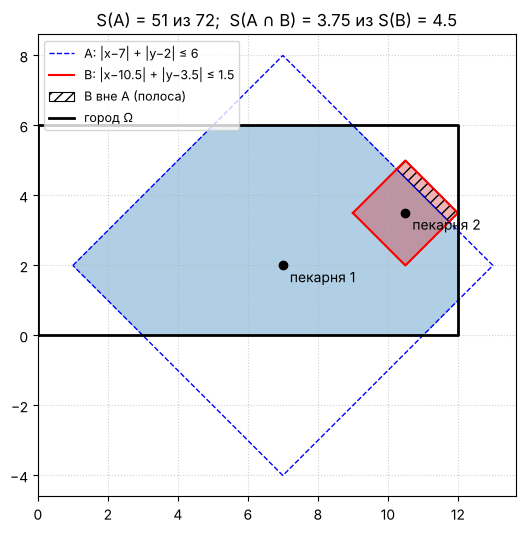

In [ ]:
# Рисунок: закрашиваем точки сетки, где выполнено A (внутри города), ромб B и отрезанную от него полосу
xs, ys = np.meshgrid(np.linspace(0, x_max, 480), np.linspace(0, y_max, 240))
mask_a = np.abs(xs - a_shop) + np.abs(ys - b_shop) <= r_max


def diamond_outline(a: float, b: float, r: float) -> Tuple[List[float], List[float]]:
    """Координаты контура ромба |x - a| + |y - b| = r (замкнутая ломаная)."""

    return [a - r, a, a + r, a, a - r], [b, b + r, b, b - r, b]


plt.figure(figsize=(8, 6))
plt.contourf(xs, ys, mask_a, levels=[0.5, 1.5], colors=["tab:blue"], alpha=0.35)
plt.plot(*diamond_outline(a_shop, b_shop, r_max), "b--", linewidth=1,
         label=f"A: |x−{a_shop:g}| + |y−{b_shop:g}| ≤ {r_max:g}")
plt.fill(*diamond_outline(a_two, b_two, r_two), color="tab:red", alpha=0.35)
plt.plot(*diamond_outline(a_two, b_two, r_two), "r-", linewidth=1.5,
         label=f"B: |x−{a_two:g}| + |y−{b_two:g}| ≤ {r_two:g}")
# Отрезанная полоса sum_a_max < x + y <= sum_b[1] (часть B вне A): сторона B, сдвинутая на δ/2 по обеим осям
plt.fill([a_two + r_two, a_two, a_two - delta / 2, a_two + r_two - delta / 2],
         [b_two, b_two + r_two, b_two + r_two - delta / 2, b_two - delta / 2],
         facecolor="none", edgecolor="k", hatch="///", linewidth=0.8, label="B вне A (полоса)")
plt.plot([0, x_max, x_max, 0, 0], [0, 0, y_max, y_max, 0], "k-", linewidth=2, label="город Ω")
plt.plot([a_shop, a_two], [b_shop, b_two], "ko")
plt.annotate("пекарня 1", (a_shop, b_shop), xytext=(5, -12), textcoords="offset points")
plt.annotate("пекарня 2", (a_two, b_two), xytext=(5, -12), textcoords="offset points")
plt.title(f"S(A) = {area_a:g} из {area_omega:g};  S(A ∩ B) = {area_ab:g} из S(B) = {area_b:g}", fontsize=12)
plt.gca().set_aspect("equal")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=9, loc="upper left")
plt.show()

In [ ]:
random.seed(5)


def in_diamond(x: float, y: float, a: float, b: float, r: float) -> bool:
    """Точка (x, y) в ромбе |x - a| + |y - b| <= r (путь по улицам от (a, b) не длиннее r)."""

    return abs(x - a) + abs(y - b) <= r


def simulate_delivery(iterations: int) -> float:
    """Оценивает P(A): доля равномерных точек города, попавших в A."""

    hits = 0
    for _ in range(iterations):
        # Равномерная точка в прямоугольнике = две независимые uniform
        x = random.uniform(0, x_max)
        y = random.uniform(0, y_max)
        hits += in_diamond(x, y, a_shop, b_shop, r_max)

    return hits / iterations


def simulate_delivery_given_second(iterations: int) -> Tuple[float, int]:
    """Оценивает P(A | B) отбором: точки вне зоны второй пекарни отбрасываются.

    Возвращает оценку и число принятых точек (эффективный объём выборки).
    """

    accepted = 0
    hits = 0
    for _ in range(iterations):
        x = random.uniform(0, x_max)
        y = random.uniform(0, y_max)
        if not in_diamond(x, y, a_two, b_two, r_two):   # условие B не выполнено — точку выбрасываем
            continue
        accepted += 1
        hits += in_diamond(x, y, a_shop, b_shop, r_max)

    return hits / accepted, accepted


num_iterations = 1_000_000
num_iterations_cond = 3_000_000

mc_prob_a = simulate_delivery(num_iterations)
mc_prob_a_given_b, n_accepted = simulate_delivery_given_second(num_iterations_cond)

for title, n, exact, mc in [
    ("P(A)", num_iterations, prob_a, mc_prob_a),
    ("P(A | B), отбор", num_iterations_cond, prob_a_given_b, mc_prob_a_given_b),
]:
    abs_diff = exact - mc
    rel_diff = abs(abs_diff / exact) * 100
    print(f"━━━ {title} (N = {n}) ━━━")
    print(f"  {'Точная вероятность:':<{w}} {exact:.6f}")
    print(f"  {'Вероятность симуляции:':<{w}} {mc:.6f}")
    print(f"  {'Абсолютная разность:':<{w}} {abs_diff:.6f}")
    print(f"  {'Относительная разность:':<{w}} {rel_diff:.4f}%")
print(f"  {'Принято точек (попали в B):':<{w}} {n_accepted}")

━━━ P(A) (N = 1000000) ━━━
  Точная вероятность:              0.708333
  Вероятность симуляции:           0.707730
  Абсолютная разность:             0.000603
  Относительная разность:          0.0852%
━━━ P(A | B), отбор (N = 3000000) ━━━
  Точная вероятность:              0.833333
  Вероятность симуляции:           0.833274
  Абсолютная разность:             0.000059
  Относительная разность:          0.0071%
  Принято точек (попали в B):      186858


---

## Задача 6. Насколько верить Монте-Карло

Покупатель берёт два товара. Их цены независимы: $x \sim U[0, 8]$, $y \sim U[0, 6]$ (тыс. руб.).
Магазин дарит подарок, если **суммарная покупка не меньше 8 тыс.** и при этом **первый товар стоил не больше 6 тыс.**:

$$A = \{x + y \ge 8\} \cap \{x \le 6\}.$$

1. Найдите точную $P(A)$. Коллега предлагает «быстрый» ответ $P(x + y \ge 8)\cdot P(x \le 6)$. Верен ли он?
2. Оцените $P(A)$ методом Монте-Карло (через `random`), посчитайте стандартную ошибку $\sigma$ и проверьте,
   какой из двух ответов согласуется с МК.
3. Проведите 100 независимых прогонов МК по $N = 10^4$. Какая доля оценок попадёт в $p \pm 1.96\sigma$?
4. Сколько итераций нужно, чтобы с вероятностью $\approx 95\%$ ошибка МК была не больше $\varepsilon = 0.001$?
5. Как всё это коротко и доказательно записать в пункт «Выводы».

### Теория

**Шаг 1. Счётчик успехов МК — биномиальная СВ.** Каждая итерация — независимое испытание Бернулли:
«успех» (точка попала в $A$) с вероятностью $p$. Значит, число успехов $S_N \sim \operatorname{Binomial}(N, p)$,
$\ \mathbb{D}S_N = Np(1-p)$, а оценка МК $\hat p = S_N / N$:

$$\mathbb{E}\hat p = p, \qquad \mathbb{D}\hat p = \frac{\mathbb{D}S_N}{N^2} = \frac{p(1-p)}{N}, \qquad
\sigma = \sqrt{\frac{p(1-p)}{N}}.$$

Ошибка убывает как $1/\sqrt{N}$: **в 100 раз больше итераций → в 10 раз точнее**. Истинное $p$ неизвестно,
поэтому в формулу подставляют $\hat p$.

**Шаг 2. Муавр–Лаплас: сколько σ — это много.** По локальной теореме при $Np(1-p) \ge 10$ столбики
$P(S_N = k)$ лежат на гауссовой кривой; вероятность интервала — сумма столбиков ≈ площадь под кривой.
Для $\hat p$ это даёт $P\big(|\hat p - p| \le z\sigma\big) \approx \operatorname{erf}(z/\sqrt2)$ — `math.erf`
считает ровно этот интеграл нормальной плотности от $-z$ до $z$: **0.95 при $z = 1.96$, 0.997 при $z = 3$.**
Правило: расхождение **до 2σ — шум**; **2–3σ — повторить с бо́льшим $N$**; **больше 3σ** — МК и формула считают
*разные* события (ошибка в коде или в аналитике).

**Шаг 3. Сколько нужно $N$; эффективный $N$.** Хотим $1.96\sigma \le \varepsilon$ ⇒
$N \ge 1.96^2\, p(1-p)/\varepsilon^2$. Если $p$ неизвестно, берут худший случай $p(1-p) \le 1/4$:
$N \ge 1.96^2/(4\varepsilon^2) \approx 9.6\cdot10^5$ при $\varepsilon = 0.001$ — отсюда «стандартные» $10^6$.
МК-оценка *условной* вероятности $\#(B \cap C)/\#C$ — частота только по итерациям, где выполнено условие; их
$N_{\text{эфф}} \approx N\cdot P(C)$. В задаче 4 $P(\text{3 орла}) \approx 0.3032$, и условие выполнилось в
$N_B = 303\,684$ итерациях из $10^6$. Поэтому ошибка оценки $q = P(H_U \mid B) \approx 0.45$ равна
$\sqrt{q(1-q)/N_B} \approx 0.0009$ — в $1/\sqrt{0.3032} \approx 1.8$ раза больше, чем была бы ошибка оценки той же
величины по всем $10^6$ итерациям ($\approx 0.0005$).

**Шаг 4. Когда нельзя перемножать.** $P(B \cap C) = P(B)\,P(C)$ — определение *независимости событий*, а не
общее правило. События от *разных* координат независимых $x, y$ (например, $\{x \le 6\}$ и $\{y \ge 3\}$)
независимы. Если же оба события зависят от общей координаты, независимость **не гарантирована** — её надо
проверить, сравнив $P(B \mid C)$ с $P(B)$.

### Решение

**Точная вероятность.** $\Omega = [0, 8]\times[0, 6]$, $S(\Omega) = 48$. При фиксированном $x$ условие
$y \ge 8 - x$ внутри $[0, 6]$ даёт отрезок длины $6 - (8 - x) = x - 2$ при $x \ge 2$ (при $x < 2$ — пусто).
Добавляем $x \le 6$:

$$S(A) = \int_2^6 (x - 2)\,dx = \frac{4^2}{2} = 8, \qquad P(A) = \frac{8}{48} = \frac{1}{6} \approx 0.1667.$$

Геометрически $A$ — прямоугольный треугольник $(2, 6)$, $(6, 6)$, $(6, 2)$ с катетами 4.

**«Быстрый» ответ.** $\{x + y \ge 8\}$ — треугольник $(2, 6)$, $(8, 6)$, $(8, 0)$ с катетами 6: $P = 18/48 = 0.375$;
$P(x \le 6) = 6/8$. Произведение $0.375\cdot0.75 = 0.28125$ — на 69% больше верного. Проверка по шагу 4:
$P(x + y \ge 8 \mid x \le 6) = 8/36 = 2/9 \approx 0.222 \ne P(x + y \ge 8) = 0.375$ — события зависимы,
произведение неверно.

In [ ]:
# A — треугольник с катетами 4; {x + y >= 8} — треугольник с катетами 6; S(Ω) = 8 · 6
area_omega = 8 * 6
p_gift = (4 ** 2 / 2) / area_omega
p_sum, p_x = (6 ** 2 / 2) / area_omega, 6 / 8
p_gift_naive = p_sum * p_x              # НЕВЕРНО: события зависимы

print(f"━━━ Точный и «быстрый» ответы ━━━")
print(f"  {'Точная P(A):':<{w}} {p_gift:.6f}")
print(f"  {'Произведение (неверно):':<{w}} {p_gift_naive:.6f}")
print(f"  {'P(x+y>=8 | x<=6):':<{w}} {p_gift / p_x:.6f}")
print(f"  {'P(x+y>=8):':<{w}} {p_sum:.6f}")

━━━ Точный и «быстрый» ответы ━━━
  Точная P(A):                     0.166667
  Произведение (неверно):          0.281250
  P(x+y>=8 | x<=6):                0.222222
  P(x+y>=8):                       0.375000


**Монте-Карло и σ.** Для каждой оценки считаем $\sigma$ по $\hat p$ и смотрим, на сколько $\sigma$ от $\hat p$
отстоят точный и «быстрый» ответы.

In [ ]:
def in_gift_zone(x: float, y: float) -> bool:
    """Событие A: сумма не меньше 8 и первый товар не дороже 6."""

    return x + y >= 8 and x <= 6


def monte_carlo_gift(iterations: int = 1_000_000) -> float:
    """Оценивает P(A) методом Монте-Карло через random.uniform."""

    hits = 0
    for _ in range(iterations):
        x = random.uniform(0, 8)   # цена первого товара
        y = random.uniform(0, 6)   # цена второго товара, независимо
        if in_gift_zone(x, y):
            hits += 1
    return hits / iterations


random.seed(2)
for n_iter in (10_000, 1_000_000):
    p_hat = monte_carlo_gift(n_iter)
    sigma_hat = math.sqrt(p_hat * (1 - p_hat) / n_iter)   # стандартная ошибка по p̂
    abs_diff = abs(p_gift - p_hat)
    rel_diff = abs_diff / p_gift * 100                    # в процентах

    print(f"━━━ Монте-Карло, N = {n_iter:,} ━━━")
    print(f"  {'Оценка МК:':<{w}} {p_hat:.6f}")
    print(f"  {'Стандартная ошибка σ:':<{w}} {sigma_hat:.6f}")
    print(f"  {'Абсолютная разность:':<{w}} {abs_diff:.6f}")
    print(f"  {'Относительная разность:':<{w}} {rel_diff:.4f}%")
    print(f"  {'Точный ответ, отклонение:':<{w}} {abs_diff / sigma_hat:.1f} σ")
    print(f"  {'«Быстрый» ответ, отклонение:':<{w}} {abs(p_gift_naive - p_hat) / sigma_hat:.1f} σ")

━━━ Монте-Карло, N = 10,000 ━━━
  Оценка МК:                       0.163400
  Стандартная ошибка σ:            0.003697
  Абсолютная разность:             0.003267
  Относительная разность:          1.9600%
  Точный ответ, отклонение:        0.9 σ
  «Быстрый» ответ, отклонение:     31.9 σ


━━━ Монте-Карло, N = 1,000,000 ━━━
  Оценка МК:                       0.166204
  Стандартная ошибка σ:            0.000372
  Абсолютная разность:             0.000463
  Относительная разность:          0.2776%
  Точный ответ, отклонение:        1.2 σ
  «Быстрый» ответ, отклонение:     309.0 σ


Точный ответ отстоит от $\hat p$ на величину порядка $\sigma$ — это шум. «Быстрый» ответ уже при $N = 10^4$
отстоит на **десятки** $\sigma$, а при $N = 10^6$ — на сотни: случайно так не бывает, ошибка в аналитике.
МК — независимая проверка формулы.

**Требуемое $N$ (п. 4).** По шагу 3 при $p = 1/6$: $N \ge 1.96^2\cdot\frac16\cdot\frac56 / 0.001^2 \approx 5.3\cdot10^5$.

**100 прогонов по $N = 10^4$.** Проверим, что $\pm1.96\sigma$ — действительно ≈ 95% ($\sigma$ по точному $p = 1/6$).
Само число попаданий из 100 ~ $\operatorname{Binomial}(100, 0.95)$, его разброс ≈ ±2, так что 93–97 — норма.

In [ ]:
random.seed(66)
n_runs, n_iter = 100, 10_000
sigma_true = math.sqrt(p_gift * (1 - p_gift) / n_iter)

# 100 независимых оценок p̂ (всего 10^6 итераций)
estimates = [monte_carlo_gift(n_iter) for _ in range(n_runs)]

share_196 = sum(abs(e - p_gift) <= 1.96 * sigma_true for e in estimates) / n_runs * 100
share_3 = sum(abs(e - p_gift) <= 3 * sigma_true for e in estimates) / n_runs * 100

print(f"━━━ {n_runs} прогонов по N = {n_iter:,} ━━━")
print(f"  {'σ при p = 1/6:':<{w}} {sigma_true:.6f}")
print(f"  {'Разброс оценок (min … max):':<{w}} {min(estimates):.4f} … {max(estimates):.4f}")
print(f"  {'Доля в p ± 1.96σ:':<{w}} {share_196:.0f}% (теория {math.erf(1.96 / math.sqrt(2)) * 100:.1f}%)")
print(f"  {'Доля в p ± 3σ:':<{w}} {share_3:.0f}% (теория {math.erf(3 / math.sqrt(2)) * 100:.1f}%)")

━━━ 100 прогонов по N = 10,000 ━━━
  σ при p = 1/6:                   0.003727
  Разброс оценок (min … max):      0.1591 … 0.1779
  Доля в p ± 1.96σ:                96% (теория 95.0%)
  Доля в p ± 3σ:                   99% (теория 99.7%)
